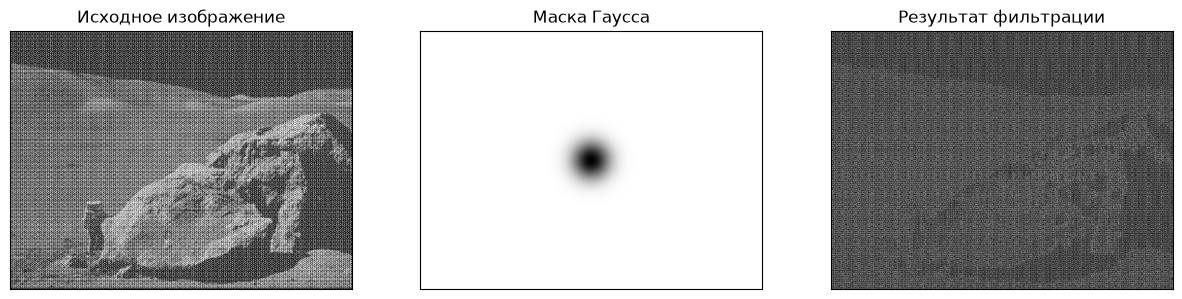

In [21]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
sigma = 30
u = np.arange(img.shape[0]) - img.shape[0]//2
v = np.arange(img.shape[1]) - img.shape[1]//2
U, V = np.meshgrid(u, v, indexing='ij')

mask_hp = 1 - np.exp(-(U**2 + V**2) / (2*sigma**2))
mask_hp = np.dstack([mask_hp, mask_hp]).astype(np.float32)

dft_hp = dft_shift * mask_hp

img_hp = cv.idft(np.fft.ifftshift(dft_hp))
img_hp = cv.magnitude(img_hp[:,:,0], img_hp[:,:,1])

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(mask_hp[:,:,0], cmap='gray')
plt.title('Маска Гаусса'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(img_hp, cmap='gray')
plt.title('Результат фильтрации'), plt.xticks([]), plt.yticks([])
plt.show()

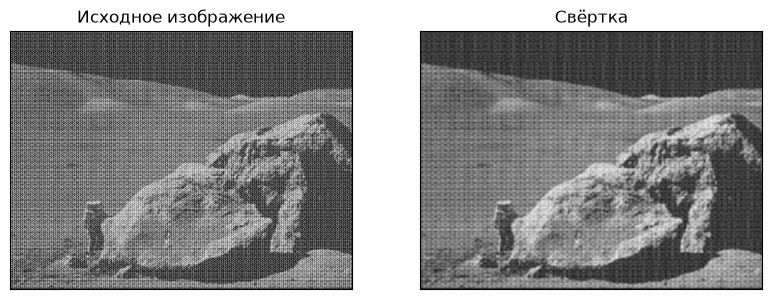

In [22]:
# Реализуйте вычисление свертки с помощью преобразования Фурье
kernel = np.ones((5, 5), np.float32) / 25

kernel_pad = np.zeros_like(img, dtype=np.float32)
kernel_pad[:5, :5] = kernel
kernel_pad = np.roll(kernel_pad, (-2, -2), axis=(0, 1))

dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(kernel_pad, flags=cv.DFT_COMPLEX_OUTPUT)

dft_conv = cv.mulSpectrums(dft_img, dft_kernel, 0)

img_conv = cv.idft(dft_conv)
img_conv = cv.magnitude(img_conv[:,:,0], img_conv[:,:,1])

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(img_conv, cmap='gray')
plt.title('Свёртка'), plt.xticks([]), plt.yticks([])
plt.show()

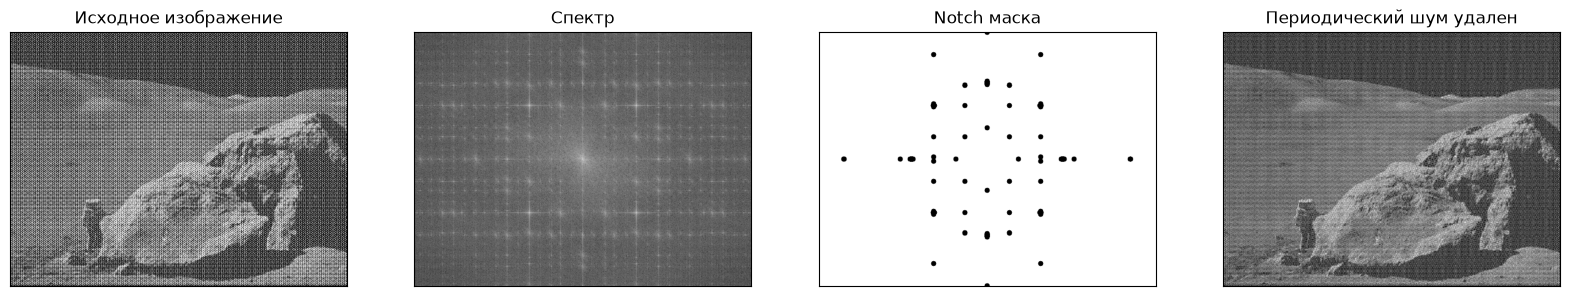

In [23]:
# Реализуйте удаление периодического шума с помощью преобразования Фурье
centerX, centerY = img.shape[0]//2, img.shape[1]//2

magnitude = 20*np.log(cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]) + 1e-6)

k = 50
magnitude[centerX-k:centerX+k, centerY-k:centerY+k] = 0
peaks = np.argwhere(magnitude > magnitude.mean() + 3*magnitude.std())

mask_notch = np.ones((img.shape[0], img.shape[1]), np.float32)
for y, x in peaks:
    cv.circle(mask_notch, (x, y), 6, 0, -1)
mask_notch = np.dstack([mask_notch, mask_notch])

dft_denoised = dft_shift * mask_notch

img_denoised = cv.idft(np.fft.ifftshift(dft_denoised))
img_denoised = cv.magnitude(img_denoised[:,:,0], img_denoised[:,:,1])

plt.figure(figsize=(20, 5))
plt.subplot(141), plt.imshow(img, cmap='gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(142), plt.imshow(20*np.log(cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]) + 1e-6), cmap='gray')
plt.title('Спектр'), plt.xticks([]), plt.yticks([])
plt.subplot(143), plt.imshow(mask_notch[:,:,0], cmap='gray')
plt.title('Notch маска'), plt.xticks([]), plt.yticks([])
plt.subplot(144), plt.imshow(img_denoised, cmap='gray')
plt.title('Периодический шум удален'), plt.xticks([]), plt.yticks([])
plt.show()